# UCI Bank Marketing — Random Forest seleccionado 

Incluye análisis exploratorio, correlaciones antes y después de One-Hot Encoding, evaluación 80/20, scoring de 0 a 100, Top 20%.
**Importante:** no se utiliza `duration` ni metadatos de carga.

**Ruta CSV:** `C:\Users\medus\Documents\out.csv`. **Salida nueva:** `RandomForest_Nuevo/`.

## 1. Librerías y configuración

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    classification_report, ConfusionMatrixDisplay)

SEED = 42
RUTA_CSV = Path(r"C:\Users\medus\Documents\out.csv")
if not RUTA_CSV.exists():
    RUTA_CSV = next((p for p in [Path('out.csv'), Path('../out.csv'), Path('/mnt/data/out.csv')] if p.exists()), RUTA_CSV)
if not RUTA_CSV.exists():
    raise FileNotFoundError(f'No se encontró: {RUTA_CSV}')
OUT = Path('RandomForest_Nuevo')
OUT.mkdir(parents=True, exist_ok=True)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Archivo:', RUTA_CSV.resolve())
print('Resultados:', OUT.resolve())

Archivo: C:\Users\medus\Documents\out.csv
Resultados: C:\Users\medus\Downloads\RandomForest_Nuevo


## 2. Cargar y limpiar los datos
Se normalizan nombres y categorías, se conserva un identificador de **registro/contacto** y se crea `pdays_contactado`. Se excluye `duration` porque no se conoce antes de llamar.

In [2]:
df = pd.read_csv(RUTA_CSV, sep=';', encoding='utf-8-sig')
df.columns = df.columns.str.strip().str.lower().str.replace('.', '_', regex=False)
df = df.rename(columns={'default':'has_default'})
for c in df.select_dtypes(include=['object', 'string']).columns:
    df[c] = df[c].astype('string').str.strip().str.lower()
df = df[df['y'].isin(['yes', 'no'])].copy()
df['id_registro'] = np.arange(1, len(df) + 1)
y = df['y'].map({'no':0, 'yes':1}).astype(int)
X = df.drop(columns=['y', 'id_registro', 'duration', 'load_ts', 'load_source',
                    'call_key', 'client_key', 'campaign_key'], errors='ignore').copy()
X['pdays'] = pd.to_numeric(X['pdays'], errors='coerce')
X['pdays_contactado'] = (X['pdays'].notna() & X['pdays'].ne(999)).astype(int)
X['pdays'] = X['pdays'].replace(999, np.nan)
for c in X.select_dtypes(exclude=['object', 'string']).columns:
    X[c] = pd.to_numeric(X[c], errors='coerce')
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
assert 'duration' not in X.columns
print('Filas:', len(X), '| Predictores:', len(X.columns))
print('Numéricas:', num_cols)
print('Categóricas:', cat_cols)
display(y.value_counts(normalize=True).rename(index={0:'No',1:'Sí'}).to_frame('proporción'))
display(X.head(5))

Filas: 41171 | Predictores: 20
Numéricas: ['age', 'campaign', 'pdays', 'previous', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'pdays_contactado']
Categóricas: ['job', 'marital', 'education', 'has_default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


,proporción
y,
No,0.887372
Sí,0.112628


,age,job,marital,education,has_default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,pdays_contactado
0,55,technician,married,professional.course,unknown,yes,no,telephone,may,mon,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,57,unknown,married,unknown,unknown,no,no,telephone,may,mon,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,57,unknown,married,unknown,unknown,yes,no,telephone,may,mon,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,35,admin.,single,high.school,no,yes,no,telephone,may,mon,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,30,blue-collar,single,unknown,no,yes,yes,telephone,may,mon,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


## 3. División 80% entrenamiento y 20% prueba
La división estratificada conserva la proporción de suscripciones. Las correlaciones y transformaciones se **ajustan solo con entrenamiento**.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Positivos en test:', int(y_test.sum()))

Entrenamiento: (32936, 20) | Prueba: (8235, 20)
Positivos en test: 927


## 4. Correlación exploratoria ANTES de One-Hot
Pearson se calcula sobre las columnas numéricas del 80% de entrenamiento. Sirve para describir asociaciones, **no para descartar automáticamente variables**.

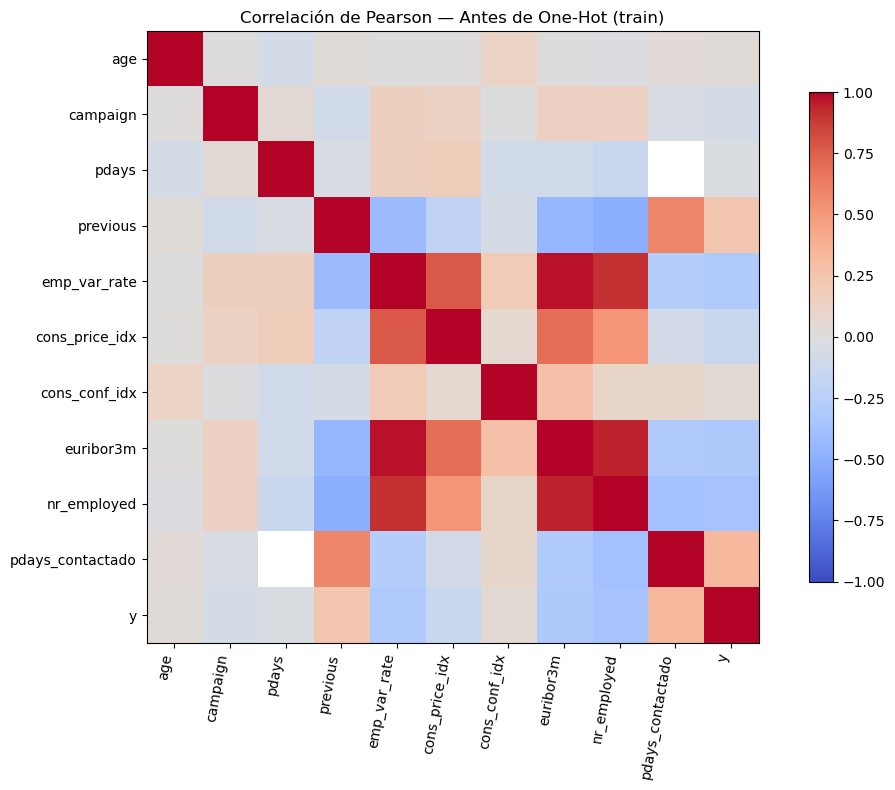

,correlacion_y
nr_employed,-0.354353
pdays_contactado,0.326383
euribor3m,-0.307674
emp_var_rate,-0.297461
previous,0.230698
cons_price_idx,-0.135385
campaign,-0.067696
cons_conf_idx,0.050348
age,0.030746
pdays,-0.026989


In [4]:
datos_corr = X_train[num_cols].copy()
datos_corr['y'] = y_train
corr_num = datos_corr.corr(numeric_only=True)
corr_num.to_csv(OUT/'correlacion_antes_onehot.csv')
fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(corr_num, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_num.columns)), labels=corr_num.columns, rotation=80, ha='right')
ax.set_yticks(range(len(corr_num.index)), labels=corr_num.index)
fig.colorbar(im, ax=ax, shrink=.8)
ax.set_title('Correlación de Pearson — Antes de One-Hot (train)')
fig.tight_layout()
fig.savefig(OUT/'correlacion_antes_onehot.png', dpi=160)
plt.show()
display(corr_num['y'].drop('y').sort_values(key=abs, ascending=False).to_frame('correlacion_y'))

## 5. One-Hot Encoding y correlación DESPUÉS
La codificación que usa el modelo está integrada en el pipeline. Para explorar las categorías se ajusta un transformador **separado y únicamente con train**, y se calcula la correlación de las columnas generadas con `y`. Esta exploración no sustituye el preprocesamiento interno del modelo.

Predictores originales: 20
Columnas después de One-Hot: 63
Columnas categóricas codificadas: 53


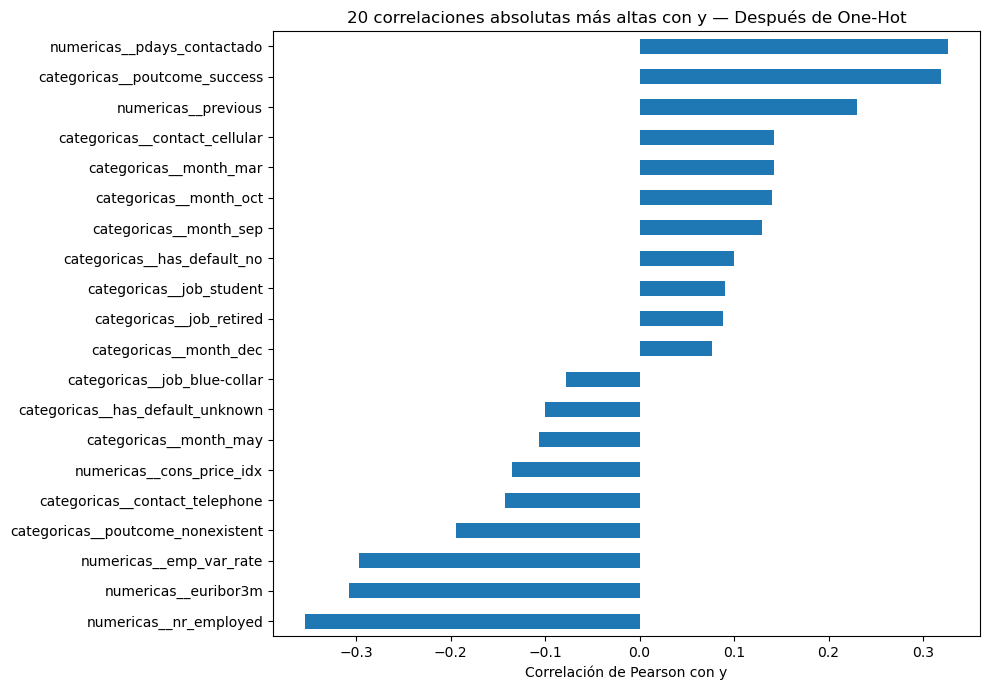

,correlacion_y
numericas__nr_employed,-0.354353
numericas__pdays_contactado,0.326383
categoricas__poutcome_success,0.318875
numericas__euribor3m,-0.307674
numericas__emp_var_rate,-0.297461
numericas__previous,0.230698
categoricas__poutcome_nonexistent,-0.194691
categoricas__contact_cellular,0.142365
categoricas__contact_telephone,-0.142365
categoricas__month_mar,0.142079


In [5]:
preprocesador = ColumnTransformer(transformers=[
    ('numericas', Pipeline([('imputar', SimpleImputer(strategy='median'))]), num_cols),
    ('categoricas', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])
explorador = preprocesador.fit(X_train)
ohe_exploratorio = explorador.transform(X_train)
if hasattr(ohe_exploratorio, 'toarray'):
    ohe_exploratorio = ohe_exploratorio.toarray()
nombres_ohe = explorador.get_feature_names_out()
encoded = pd.DataFrame(ohe_exploratorio, columns=nombres_ohe, index=X_train.index)
print('Predictores originales:', X_train.shape[1])
print('Columnas después de One-Hot:', encoded.shape[1])
print('Columnas categóricas codificadas:', encoded.shape[1] - len(num_cols))
correlaciones_ohe = encoded.corrwith(y_train).dropna().sort_values(key=abs, ascending=False)
correlaciones_ohe.rename('correlacion_y').to_csv(OUT/'correlacion_despues_onehot.csv')
fig, ax = plt.subplots(figsize=(10,7))
correlaciones_ohe.head(20).sort_values().plot.barh(ax=ax)
ax.set_title('20 correlaciones absolutas más altas con y — Después de One-Hot')
ax.set_xlabel('Correlación de Pearson con y')
fig.tight_layout(); fig.savefig(OUT/'correlacion_despues_onehot_top20.png', dpi=160); plt.show()
display(correlaciones_ohe.head(20).to_frame('correlacion_y'))

## 6. Modelo único: Random Forest

- Árboles: **250**; profundidad máxima: **20**.
- Mínimo de muestras para dividir: **12**; por hoja: **6**.
- Atributos por división: **sqrt**; criterio: **gini**; bootstrap: **True**.
- Pesos de clases: **{0: 1, 1: 5}** (ponderación personalizada de la clase `yes`).

In [6]:
parametros_rf = {
    'n_estimators': 250,
    'max_depth': 20,
    'min_samples_split': 12,
    'min_samples_leaf': 6,
    'max_features': 'sqrt',
    'criterion': 'gini',
    'class_weight': {0: 1, 1: 5},
    'bootstrap': True,
    'random_state': SEED,
    'n_jobs': 1
}
modelo = Pipeline([
    ('preprocesamiento', preprocesador),
    ('clf', RandomForestClassifier(**parametros_rf))
])
print('Modelo:', type(modelo.named_steps['clf']).__name__)
print('Hiperparámetros:', parametros_rf)

Modelo: RandomForestClassifier
Hiperparámetros: {'n_estimators': 250, 'max_depth': 20, 'min_samples_split': 12, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'criterion': 'gini', 'class_weight': {0: 1, 1: 5}, 'bootstrap': True, 'random_state': 42, 'n_jobs': 1}


## 7. Umbral para F1 (solo entrenamiento)
Se generan probabilidades fuera de fold en **5 particiones del 80% de entrenamiento**. La CV requiere ajustes internos temporales, pero **solo se entrena una configuración** y no se hace otra búsqueda. El test permanece aislado.

Umbral F1 seleccionado con train OOF: 0.5167
F1 OOF de referencia: 0.5057


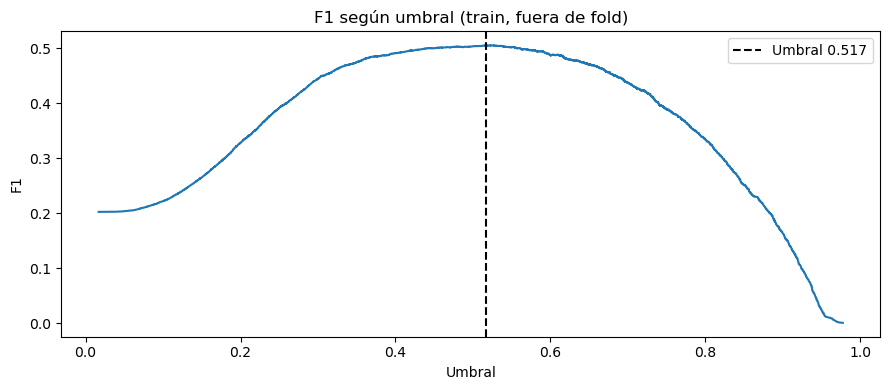

In [7]:
prob_oof = cross_val_predict(modelo, X_train, y_train, cv=CV,
                               method='predict_proba', n_jobs=1)[:,1]
precision_cv, recall_cv, thresholds = precision_recall_curve(y_train, prob_oof)
f1_curva = (2*precision_cv[:-1]*recall_cv[:-1] /
            (precision_cv[:-1]+recall_cv[:-1]+1e-12))
idx = int(np.argmax(f1_curva))
umbral_f1 = float(thresholds[idx])
print(f'Umbral F1 seleccionado con train OOF: {umbral_f1:.4f}')
print(f'F1 OOF de referencia: {f1_curva[idx]:.4f}')
pd.DataFrame({'umbral':thresholds, 'f1_train_oof':f1_curva}).to_csv(OUT/'curva_umbral_f1_train.csv', index=False)
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(thresholds, f1_curva)
ax.axvline(umbral_f1, color='black', linestyle='--', label=f'Umbral {umbral_f1:.3f}')
ax.set(xlabel='Umbral',ylabel='F1',title='F1 según umbral (train, fuera de fold)')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'f1_por_umbral_train.png',dpi=160); plt.show()

## 8. Único ajuste final y evaluación independiente en test
Se ajusta el modelo con las 32.936 filas de entrenamiento y se evalúa una vez en las 8.235 filas de prueba. Comparamos umbral estándar y el elegido para F1.

,configuracion,accuracy,precision_yes,recall_yes,F1_yes,ROC_AUC,PR_AUC
0,Umbral 0.50,0.8763,0.4617,0.5976,0.5209,0.8049,0.477
1,Umbral F1 entrenado,0.8783,0.4680,0.5922,0.5229,0.8049,0.477


              precision    recall  f1-score   support

          no       0.95      0.91      0.93      7308
         yes       0.47      0.59      0.52       927

    accuracy                           0.88      8235
   macro avg       0.71      0.75      0.73      8235
weighted avg       0.89      0.88      0.88      8235



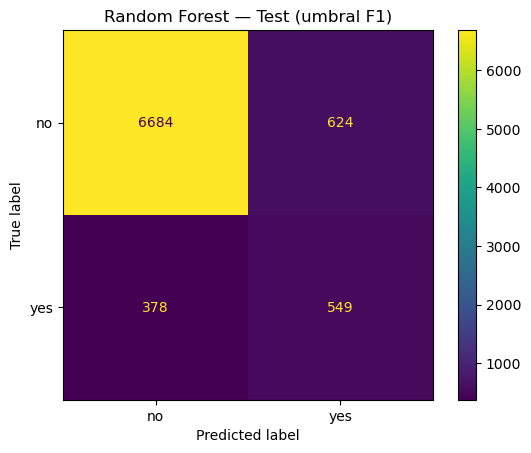

In [8]:
modelo.fit(X_train, y_train)
prob_test = modelo.predict_proba(X_test)[:,1]
y_pred_05 = (prob_test >= 0.50).astype(int)
y_pred_f1 = (prob_test >= umbral_f1).astype(int)
def evaluar(etiqueta, pred):
    return {'configuracion': etiqueta,
            'accuracy': accuracy_score(y_test,pred),
            'precision_yes': precision_score(y_test,pred,zero_division=0),
            'recall_yes': recall_score(y_test,pred,zero_division=0),
            'F1_yes': f1_score(y_test,pred,zero_division=0),
            'ROC_AUC': roc_auc_score(y_test,prob_test),
            'PR_AUC': average_precision_score(y_test,prob_test)}
metricas_test = pd.DataFrame([evaluar('Umbral 0.50',y_pred_05),
                              evaluar('Umbral F1 entrenado',y_pred_f1)])
display(metricas_test.round(4))
metricas_test.to_csv(OUT/'metricas_test.csv',index=False)
print(classification_report(y_test,y_pred_f1,target_names=['no','yes'],zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_f1,display_labels=['no','yes'])
plt.title('Random Forest — Test (umbral F1)')
plt.savefig(OUT/'matriz_confusion_test.png',dpi=160,bbox_inches='tight')
plt.show()

## 9. Propensión de 0 a 100 y Top 20%
Se exportan las predicciones de los **contactos del conjunto test**, junto con sus características originales, `y_real`, probabilidad y scoring. El Top 20% son aproximadamente **1.647 registros** (no 20 personas). `id_registro` identifica una fila, **no necesariamente un cliente único**. El ranking es independiente del umbral F1.

,registros_test,registros_top20,suscripciones_test,suscripciones_top20,precision_at_20,recall_at_20,lift_at_20,tasa_yes_general
0,8235,1647,927,613,0.3722,0.6613,3.3064,0.1126


,id_registro,scoring_0_100,prediccion_yes,y_real,top20,prioridad
0,29534,96.38,1,1,1,Alta - Top 20%
1,19984,96.28,1,1,1,Alta - Top 20%
2,21397,96.18,1,1,1,Alta - Top 20%
3,32841,96.14,1,1,1,Alta - Top 20%
4,28889,95.85,1,1,1,Alta - Top 20%
5,29794,95.82,1,0,1,Alta - Top 20%
6,38475,95.82,1,1,1,Alta - Top 20%
7,24058,95.68,1,1,1,Alta - Top 20%
8,19905,95.68,1,0,1,Alta - Top 20%
9,32850,95.67,1,0,1,Alta - Top 20%


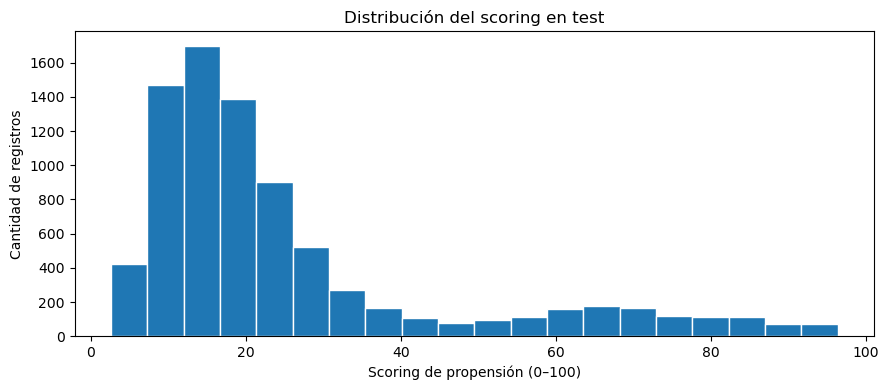

In [9]:
scoring = X_test.copy()
scoring.insert(0, 'id_registro', df.loc[X_test.index, 'id_registro'].to_numpy())
scoring['y_real'] = y_test.to_numpy()
scoring['probabilidad_yes'] = prob_test
scoring['scoring_0_100'] = (prob_test*100).round(2)
scoring['prediccion_yes'] = y_pred_f1
scoring = scoring.sort_values(['probabilidad_yes','id_registro'],ascending=[False,True]).reset_index(drop=True)
n_top = int(np.ceil(len(scoring)*.20))
scoring['top20'] = 0
scoring.loc[:n_top-1, 'top20'] = 1
scoring['prioridad'] = np.where(scoring['top20'].eq(1), 'Alta - Top 20%', 'Resto')
scoring.to_csv(OUT/'scoring_test_0_100.csv', index=False, encoding='utf-8-sig')
top20 = scoring[scoring['top20'].eq(1)].copy()
top20.to_csv(OUT/'top20_clientes_test.csv', index=False, encoding='utf-8-sig')
precision20 = float(top20['y_real'].mean())
recall20 = float(top20['y_real'].sum()/scoring['y_real'].sum())
tasa_general = float(scoring['y_real'].mean())
lift20 = precision20/tasa_general if tasa_general else np.nan
met_top20 = pd.DataFrame([{'registros_test':len(scoring), 'registros_top20':n_top,
    'suscripciones_test':int(scoring['y_real'].sum()),
    'suscripciones_top20':int(top20['y_real'].sum()),
    'precision_at_20':precision20, 'recall_at_20':recall20,
    'lift_at_20':lift20, 'tasa_yes_general':tasa_general}])
met_top20.to_csv(OUT/'metricas_top20.csv',index=False)
display(met_top20.round(4))
display(scoring[['id_registro','scoring_0_100','prediccion_yes','y_real','top20','prioridad']].head(10))
fig,ax=plt.subplots(figsize=(9,4))
ax.hist(scoring['scoring_0_100'], bins=20, edgecolor='white')
ax.set(xlabel='Scoring de propensión (0–100)',ylabel='Cantidad de registros',title='Distribución del scoring en test')
fig.tight_layout();fig.savefig(OUT/'distribucion_scoring_test.png',dpi=160);plt.show()

## 10. Guardar el modelo entrenado (`.joblib`) y configuración
El archivo guarda el **pipeline completo** con imputación, One-Hot Encoding, Random Forest y el umbral definido a partir de entrenamiento. No es un CSV y no se importa directamente en Tableau.

In [10]:
paquete = {'modelo': modelo, 'umbral_f1': umbral_f1,
           'columnas': X.columns.tolist(), 'parametros': parametros_rf,
           'sin_duration': True, 'seed':SEED}
joblib.dump(paquete, OUT/'RandomForest_balanceado.joblib')
with open(OUT/'configuracion_modelo.json','w',encoding='utf-8') as f:
    json.dump({'modelo':'RandomForest_balanceado', 'hiperparametros':parametros_rf,
       'umbral_f1':umbral_f1, 'sin_duration':True,
       'f1_test_umbral_f1': float(metricas_test.iloc[1]['F1_yes']),
       'precision_at_20':precision20,'recall_at_20':recall20,'lift_at_20':lift20},
       f, ensure_ascii=False, indent=2) 
print('Modelo guardado:',(OUT/'RandomForest_balanceado.joblib').resolve())

Modelo guardado: C:\Users\medus\Downloads\RandomForest_Nuevo\RandomForest_balanceado.joblib


## 11. ¿Qué se guarda en cada archivo?

**Carpeta:** `RandomForest_Nuevo/`

| Archivo | Contenido / utilidad |
|---|---|
| **`RandomForest_balanceado.joblib`** | Pipeline entrenado, imputación, One-Hot Encoding, hiperparámetros, columnas y umbral F1 para reutilizar predicciones. |
| **`metricas_test.csv`** | Accuracy, Precision, Recall, **F1 yes**, ROC-AUC y PR-AUC en test, para umbral 0.50 y umbral F1. |
| **`scoring_test_0_100.csv`** | Todos los registros de test con variables originales, predicción, probabilidad, scoring, Top 20% y prioridad. **Fuente principal para Tableau.** |
| **`top20_clientes_test.csv`** | Subconjunto de contactos con las mayores probabilidades para priorizar. |
| **`metricas_top20.csv`** | Precision@20, Recall@20, Lift@20 y cantidades del grupo priorizado. |
| `correlacion_antes_onehot.csv/.png` | Matriz de correlación de variables numéricas del entrenamiento. |
| `correlacion_despues_onehot.csv` | Correlación con `y` para columnas numéricas y binarias transformadas. |
| `correlacion_despues_onehot_top20.png` | Gráfico de las 20 asociaciones absolutas más altas con `y`. |
| `curva_umbral_f1_train.csv` | F1 calculado para cada umbral sobre predicciones fuera de fold. |
| `f1_por_umbral_train.png` | Gráfico del umbral F1 elegido solo con train. |
| `matriz_confusion_test.png` | Aciertos y errores del modelo en test. |
| `distribucion_scoring_test.png` | Histograma de propensión de 0 a 100 para Tableau/informe. |
| `configuracion_modelo.json` | Parámetros exactos, umbral y resumen de métricas. |

**Precaución:** estos datos corresponden a contactos del conjunto de prueba. No son una lista nueva de clientes sin contactar; para usar el `.joblib` en producción hay que proporcionarle datos previos a la llamada con las mismas columnas y validar sus probabilidades.

In [11]:
print('Carpeta final:',OUT.resolve())
for archivo in sorted(OUT.iterdir()):
    print('-', archivo.name)

Carpeta final: C:\Users\medus\Downloads\RandomForest_Nuevo
- configuracion_modelo.json
- correlacion_antes_onehot.csv
- correlacion_antes_onehot.png
- correlacion_despues_onehot.csv
- correlacion_despues_onehot_top20.png
- curva_umbral_f1_train.csv
- distribucion_scoring_test.png
- f1_por_umbral_train.png
- matriz_confusion_test.png
- metricas_test.csv
- metricas_top20.csv
- RandomForest_balanceado.joblib
- scoring_test_0_100.csv
- top20_clientes_test.csv
